# **Perbandingan Logistic Regression vs Random Forest pada Klasifikasi Kanker Payudara**

**Tugas:** Mengubah pembagian data menjadi 70% training dan 30% testing, mengganti/membandingkan algoritma Logistic Regression dengan Random Forest Classifier, lalu mengevaluasi keduanya menggunakan accuracy, precision, recall, F1-score, ROC-AUC, dan Confusion Matrix.

**Dataset:** Breast Cancer Wisconsin (569 sampel, 30 fitur numerik) dari Scikit-learn.
- Malignant (0): tumor ganas
- Benign (1): tumor jinak

**Alur pengerjaan:**
1. Import Libraries
2. Load Dataset
3. Exploratory Data Analysis
4. Dataset Splitting (70/30)
5. Pembuatan Model (Logistic Regression & Random Forest)
6. Prediksi
7. Evaluasi (Accuracy, Precision, Recall, F1-Score, ROC-AUC)
8. Confusion Matrix kedua algoritma
9. Perbandingan & Analisis
10. Validasi tambahan (Cross-Validation)
11. Mengapa Accuracy saja tidak cukup
12. Kesimpulan

## **Step 1: Import Libraries**

Langkah pertama adalah mengimpor seluruh library yang dibutuhkan. Dibandingkan contoh sebelumnya, ada penambahan `RandomForestClassifier` (algoritma baru), `precision_score`, `recall_score`, `f1_score` (metrik evaluasi terpisah agar mudah dibandingkan), serta `cross_val_score` untuk validasi tambahan.

In [ ]:
# Library untuk pengolahan data numerik dan tabel
import numpy as np
import pandas as pd

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_breast_cancer

# Pembagian data, pipeline, normalisasi
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Dua algoritma yang dibandingkan
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Metrik evaluasi
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

print("Semua librari berhasil dimasukkan")

Semua librari berhasil dimasukkan


## **Step 2: Load Dataset**

Dataset dimuat dengan `load_breast_cancer()` lalu diubah menjadi DataFrame Pandas agar mudah dianalisis.

- `X` = tabel 30 fitur (radius, texture, perimeter, area, dst.)
- `y` = label target (0 = Malignant, 1 = Benign)

In [ ]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)
print("\nFirst 5 Samples:")
display(X.head())
print("\nTarget Classes:", data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target Classes: ['malignant' 'benign']


## **Step 3: Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) merupakan proses eksplorasi dataset untuk memahami karakteristik data sebelum digunakan dalam proses pelatihan model Machine Learning.

Pada tahap ini, kita akan memeriksa:

Jumlah sampel pada setiap kelas.
Distribusi data.
Nilai yang hilang (missing values).
Karakteristik fitur yang digunakan.

In [ ]:
print("Missing Values (total):", X.isnull().sum().sum())
print()
X.info()

Missing Values (total): 0

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness

Class Distribution:
Malignant (0)    212
Benign (1)       357
Name: count, dtype: int64

Proporsi:
Malignant (0)    37.26
Benign (1)       62.74
Name: count, dtype: float64


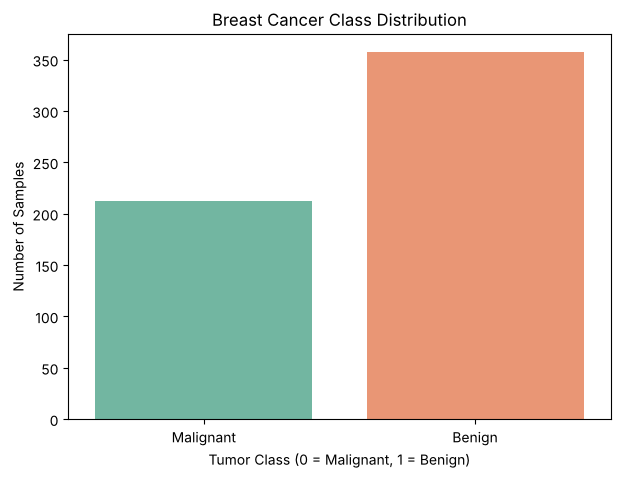

In [ ]:
class_counts = pd.Series(y).value_counts().sort_index()
print("Class Distribution:")
print(class_counts.rename({0: "Malignant (0)", 1: "Benign (1)"}))
print("\nProporsi:")
print((class_counts / len(y) * 100).round(2).rename({0: "Malignant (0)", 1: "Benign (1)"}))

plt.figure(figsize=(7, 5))
sns.countplot(x=y, hue=y, palette="Set2", legend=False)
plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.show()

**Interpretasi:** Tidak ada missing values. Kelas Benign (212 vs 357 → sekitar 63%) lebih banyak daripada Malignant (sekitar 37%), sehingga data **cukup tidak seimbang (imbalanced)**. Model yang selalu menebak "Benign" saja sudah akan mendapat accuracy sekitar 63%.

## **Step 4: Dataset Splitting (70% Training, 30% Testing)**

Perubahan dari contoh: `test_size` diubah dari `0.2` menjadi `0.3`.

- `test_size=0.3` → 30% data untuk pengujian, 70% untuk pelatihan
- `random_state=42` → hasil pembagian selalu sama (reproducible)
- `stratify=y` → proporsi Malignant/Benign di training dan testing tetap sama dengan data asli

Dengan 569 sampel: sekitar 398 data training dan 171 data testing.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples :", X_test.shape[0])
print("\nTraining Features:", X_train.shape)
print("Testing Features :", X_test.shape)
print("\nDistribusi kelas data testing:")
print(pd.Series(y_test).value_counts().sort_index().rename({0: "Malignant", 1: "Benign"}))

Training Samples: 398
Testing Samples : 171

Training Features: (398, 30)
Testing Features : (171, 30)

Distribusi kelas data testing:
Malignant     64
Benign       107
Name: count, dtype: int64


## **Step 5: Data Normalization (Feature Scaling)**

Dua model dibuat dari data training yang sama.

**Model 1: Logistic Regression (dengan StandardScaler dalam Pipeline)**
Logistic Regression sensitif terhadap skala fitur (misalnya `area` bernilai ratusan sedangkan `smoothness` bernilai sekitar 0,1), sehingga fitur distandardisasi: $z = \frac{x-\mu}{\sigma}$. Pipeline memastikan scaler hanya belajar dari data training (mencegah *data leakage*).

**Model 2: Random Forest Classifier**
Random Forest adalah kumpulan banyak pohon keputusan (*ensemble*) yang hasilnya digabung lewat voting. Algoritma berbasis pohon **tidak memerlukan standardisasi** karena pemisahan dilakukan berdasarkan ambang nilai, bukan jarak atau gradien.
- `n_estimators=100` → jumlah pohon
- `random_state=42` → hasil konsisten

In [ ]:
# Model 1: Logistic Regression
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
lr_model.fit(X_train, y_train)
print("Logistic Regression: training selesai")

# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("Random Forest      : training selesai")

Logistic Regression: training selesai
Random Forest      : training selesai


## **Step 6: Model Prediction**

Kedua model memprediksi kelas data testing (yang belum pernah dilihat saat training). `predict()` menghasilkan kelas, `predict_proba()` menghasilkan probabilitas kelas 1 (Benign) yang dipakai untuk ROC-AUC.

In [ ]:
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Prediksi Logistic Regression (20 pertama):", y_pred_lr[:20])
print("Prediksi Random Forest       (20 pertama):", y_pred_rf[:20])
print("Label sebenarnya             (20 pertama):", y_test[:20])

Prediksi Logistic Regression (20 pertama): [0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1]
Prediksi Random Forest       (20 pertama): [0 1 1 0 1 0 1 0 1 0 1 1 0 1 1 0 0 0 1 1]
Label sebenarnya             (20 pertama): [0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1]


## **Step 7: Model Evaluation**

Metrik yang digunakan:

| Metrik | Rumus | Arti |
|---|---|---|
| Accuracy | (TP+TN)/(TP+TN+FP+FN) | Persentase prediksi benar secara keseluruhan |
| Precision | TP/(TP+FP) | Dari semua yang diprediksi positif, berapa yang benar |
| Recall | TP/(TP+FN) | Dari semua yang sebenarnya positif, berapa yang berhasil ditemukan |
| F1-Score | 2·P·R/(P+R) | Rata-rata harmonik precision dan recall |
| ROC-AUC | luas area kurva ROC | Kemampuan membedakan dua kelas pada berbagai threshold |

**Catatan penting:** secara default scikit-learn menganggap kelas 1 (Benign) sebagai kelas positif. Namun dalam konteks kanker, yang paling penting ditemukan adalah **Malignant**. Karena itu selain metrik default (Benign sebagai positif), kita juga menghitung precision, recall, dan F1 untuk **Malignant** dengan `pos_label=0`.

In [ ]:
def evaluate(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Benign)": precision_score(y_true, y_pred),
        "Recall (Benign)": recall_score(y_true, y_pred),
        "F1 (Benign)": f1_score(y_true, y_pred),
        "Precision (Malignant)": precision_score(y_true, y_pred, pos_label=0),
        "Recall (Malignant)": recall_score(y_true, y_pred, pos_label=0),
        "F1 (Malignant)": f1_score(y_true, y_pred, pos_label=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

results = pd.DataFrame([
    evaluate("Logistic Regression", y_test, y_pred_lr, y_prob_lr),
    evaluate("Random Forest", y_test, y_pred_rf, y_prob_rf),
]).set_index("Model")

display(results.round(4).T)

print("Accuracy Logistic Regression: %.2f%%" % (results.loc["Logistic Regression", "Accuracy"] * 100))
print("Accuracy Random Forest      : %.2f%%" % (results.loc["Random Forest", "Accuracy"] * 100))

Model,Logistic Regression,Random Forest
Accuracy,0.9883,0.9357
Precision (Benign),0.9907,0.9444
Recall (Benign),0.9907,0.9533
F1 (Benign),0.9907,0.9488
Precision (Malignant),0.9844,0.9206
Recall (Malignant),0.9844,0.9062
F1 (Malignant),0.9844,0.9134
ROC-AUC,0.9981,0.9913


Accuracy Logistic Regression: 98.83%
Accuracy Random Forest      : 93.57%


In [ ]:
print("=== Classification Report: Logistic Regression ===")
print(classification_report(y_test, y_pred_lr, target_names=data.target_names))
print("=== Classification Report: Random Forest ===")
print(classification_report(y_test, y_pred_rf, target_names=data.target_names))

=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

=== Classification Report: Random Forest ===


              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



## **Step 8: Confusion Matrix Kedua Algoritma**

Confusion Matrix membandingkan prediksi dengan kelas sebenarnya. Baris = kelas sebenarnya, kolom = kelas prediksi. Urutan label: Malignant (0), Benign (1).

|  | Prediksi Malignant | Prediksi Benign |
|---|---|---|
| **Sebenarnya Malignant** | Benar (ganas terdeteksi) | **Kesalahan berbahaya**: ganas dikira jinak |
| **Sebenarnya Benign** | Salah alarm: jinak dikira ganas | Benar |

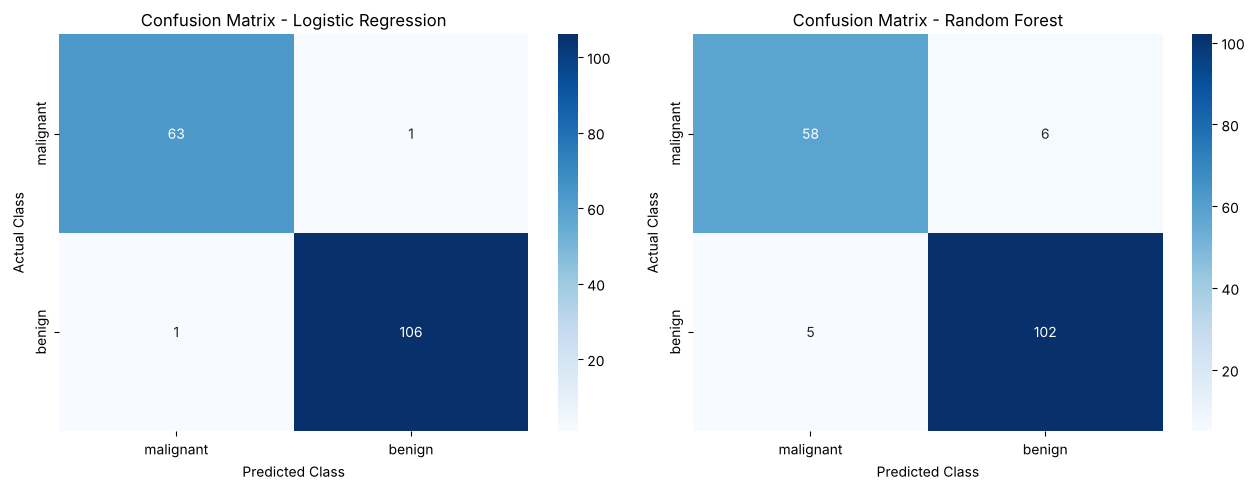

Logistic Regression:
  Malignant terdeteksi benar        : 63
  Malignant salah dikira Benign (FN klinis): 1  <-- paling berbahaya
  Benign salah dikira Malignant     : 1
  Benign terdeteksi benar           : 106

Random Forest:
  Malignant terdeteksi benar        : 58
  Malignant salah dikira Benign (FN klinis): 6  <-- paling berbahaya
  Benign salah dikira Malignant     : 5
  Benign terdeteksi benar           : 102



In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, title in zip(axes, [cm_lr, cm_rf], ["Logistic Regression", "Random Forest"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=data.target_names, yticklabels=data.target_names, ax=ax)
    ax.set_title(f"Confusion Matrix - {title}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
plt.tight_layout()
plt.show()

for name, cm in [("Logistic Regression", cm_lr), ("Random Forest", cm_rf)]:
    print(f"{name}:")
    print(f"  Malignant terdeteksi benar        : {cm[0,0]}")
    print(f"  Malignant salah dikira Benign (FN klinis): {cm[0,1]}  <-- paling berbahaya")
    print(f"  Benign salah dikira Malignant     : {cm[1,0]}")
    print(f"  Benign terdeteksi benar           : {cm[1,1]}\n")

## **Step 9: Predict a New Sample**

Visualisasi berikut membandingkan semua metrik kedua algoritma.

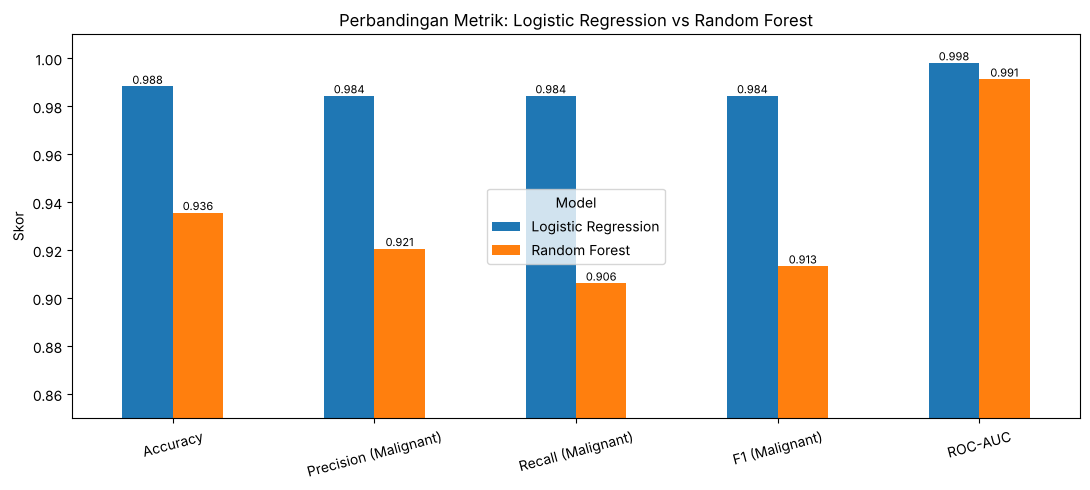

In [ ]:
metrics_plot = ["Accuracy", "Precision (Malignant)", "Recall (Malignant)", "F1 (Malignant)", "ROC-AUC"]
ax = results[metrics_plot].T.plot(kind="bar", figsize=(11, 5), rot=15)
ax.set_ylim(0.85, 1.01)
ax.set_title("Perbandingan Metrik: Logistic Regression vs Random Forest")
ax.set_ylabel("Skor")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
best = results["Accuracy"].idxmax()
print("Model dengan accuracy tertinggi:", best)
fn_lr, fn_rf = cm_lr[0, 1], cm_rf[0, 1]
print(f"Malignant yang terlewat -> Logistic Regression: {fn_lr}, Random Forest: {fn_rf}")

Model dengan accuracy tertinggi: Logistic Regression
Malignant yang terlewat -> Logistic Regression: 1, Random Forest: 6


### **Analisis Hasil**

Pada eksperimen ini (split 70/30, `random_state=42`):

| Metrik | Logistic Regression | Random Forest |
|---|---|---|
| Accuracy | **98,83%** | 93,57% |
| Precision (Malignant) | **98,44%** | 92,06% |
| Recall (Malignant) | **98,44%** | 90,63% |
| F1-Score (Malignant) | **98,44%** | 91,34% |
| ROC-AUC | **0,998** | 0,991 |
| Malignant terlewat (dikira jinak) | **1** | 6 |
| Benign salah dikira ganas | 1 | 5 |

**Kesimpulan analisis:** Logistic Regression memberikan hasil klasifikasi yang lebih baik pada eksperimen ini. Dari 171 data testing, Logistic Regression hanya salah 2 sampel, sedangkan Random Forest salah 11 sampel. Yang paling penting secara klinis, Random Forest melewatkan 6 tumor ganas (dikira jinak), jauh lebih banyak daripada Logistic Regression (1 sampel).

**Mengapa Logistic Regression bisa lebih baik di sini?**
1. Dataset ini berukuran kecil (569 sampel) dan berdimensi 30 fitur yang sebagian besar berkorelasi tinggi. Batas keputusan antara tumor ganas dan jinak pada dataset ini hampir **linear separable**, sehingga model linear sudah sangat cocok.
2. Dengan data training hanya 398 sampel, Random Forest yang kompleks cenderung tidak mendapat keuntungan dari kemampuan non-liniernya, dan lebih rentan terhadap variasi pembagian data.
3. Logistic Regression dibantu standardisasi, sehingga optimisasinya stabil.

**Catatan kejujuran ilmiah:** Hasil ini tidak berarti Random Forest selalu lebih buruk. Random Forest tanpa tuning (`n_estimators=100`, parameter default) belum tentu optimal, dan hasil pada satu kali split bisa berubah jika `random_state` diganti. Karena itu dilakukan validasi tambahan pada Step 10.

## **Step 10: Validasi Tambahan dengan Cross-Validation**

Hasil dari satu kali pembagian data bisa kebetulan menguntungkan satu model. Dengan 5-fold stratified cross-validation, setiap model diuji 5 kali pada pembagian data yang berbeda, lalu diambil rata-rata dan simpangan bakunya. Ini membuat kesimpulan lebih dapat dipercaya.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

rows = []
for name, m in models.items():
    acc = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    rec_m = cross_val_score(m, X, y, cv=cv, scoring="recall_macro")
    f1_m = cross_val_score(m, X, y, cv=cv, scoring="f1_macro")
    rows.append({"Model": name,
                 "Accuracy (mean)": acc.mean(), "Accuracy (std)": acc.std(),
                 "Recall macro (mean)": rec_m.mean(), "F1 macro (mean)": f1_m.mean()})

cv_results = pd.DataFrame(rows).set_index("Model")
display(cv_results.round(4))

,Accuracy (mean),Accuracy (std),Recall macro (mean),F1 macro (mean)
Model,,,,
Logistic Regression,0.9737,0.0166,0.9676,0.9714
Random Forest,0.9561,0.0123,0.9527,0.9529


**Interpretasi:** Hasil cross-validation memperlihatkan pola yang sama: Logistic Regression (sekitar 97,4%) tetap sedikit di atas Random Forest (sekitar 95,6%). Artinya keunggulan Logistic Regression bukan kebetulan dari satu kali split, meskipun selisihnya pada cross-validation lebih kecil dibanding pada split 70/30.

## **Step 11: Mengapa Evaluasi Tidak Cukup Hanya Menggunakan Accuracy?**

Dalam klasifikasi kanker, accuracy saja menyesatkan karena beberapa alasan:

1. **Accuracy tidak membedakan jenis kesalahan.** Ada dua kesalahan yang bobot dampaknya sangat berbeda:
   - *False Negative klinis*: tumor ganas diprediksi jinak. Pasien tidak mendapat penanganan, kanker berkembang, risikonya adalah keselamatan jiwa.
   - *False Positive klinis*: tumor jinak diprediksi ganas. Pasien menjalani pemeriksaan lanjutan (biopsi) yang tidak perlu, menimbulkan biaya dan kecemasan, tetapi tidak fatal.
   Accuracy memperlakukan keduanya sama (sama-sama "1 kesalahan"). Pada hasil kita, selisih accuracy tampak "hanya" 5 poin persen, padahal jumlah tumor ganas yang terlewat naik dari 1 menjadi 6.

2. **Data tidak seimbang.** Sekitar 63% sampel adalah Benign. Model yang selalu menebak "Benign" mendapat accuracy sekitar 63% tanpa mendeteksi satu pun tumor ganas. Pada penyakit langka (misalnya prevalensi 1%), model yang menebak "sehat" untuk semua orang bisa mencapai accuracy 99% namun tidak berguna sama sekali.

3. **Recall (sensitivitas) pada kelas Malignant adalah metrik kunci.** Recall menjawab: "dari semua pasien yang benar-benar menderita kanker ganas, berapa persen yang berhasil terdeteksi?" Dalam skrining kanker, tujuan utama adalah meminimalkan kasus ganas yang terlewat.

4. **Precision menjaga agar tidak terlalu banyak alarm palsu**, dan **F1-Score** menyeimbangkan precision dan recall dalam satu angka, terutama berguna saat kelas tidak seimbang.

5. **ROC-AUC** menilai kualitas pemisahan kelas pada semua threshold, sehingga tidak bergantung pada satu ambang keputusan (default 0,5) yang mungkin tidak ideal untuk kebutuhan klinis. Dalam praktik, threshold bisa diturunkan agar recall Malignant naik, dengan konsekuensi lebih banyak false positive.

6. **Confusion Matrix** memperlihatkan secara rinci *di mana* kesalahan terjadi, sesuatu yang tidak terlihat dari satu angka accuracy.

**Kesimpulan:** Evaluasi model medis harus menggabungkan accuracy, precision, recall (terutama untuk kelas ganas), F1-score, ROC-AUC, dan confusion matrix, serta mempertimbangkan biaya klinis dari setiap jenis kesalahan.

## **Step 12: Kesimpulan Hasil Eksperimen**

1. **Pembagian data** diubah menjadi 70% training (398 sampel) dan 30% testing (171 sampel) dengan stratifikasi.
2. **Dua algoritma** diuji: Logistic Regression (dengan StandardScaler) dan Random Forest (100 pohon).
3. **Hasil utama** pada data testing: Logistic Regression accuracy 98,83% (hanya 2 kesalahan), Random Forest 93,57% (11 kesalahan).
4. **Confusion Matrix:** Logistic Regression hanya melewatkan 1 tumor ganas, Random Forest melewatkan 6 tumor ganas.
5. **Metrik lain** (precision, recall, F1, ROC-AUC) secara konsisten juga lebih tinggi pada Logistic Regression.
6. **Cross-validation 5-fold** mengonfirmasi tren yang sama (sekitar 97,4% vs 95,6%).
7. **Algoritma terbaik pada eksperimen ini: Logistic Regression**, terutama karena dataset berukuran kecil dan hampir linear separable.
8. **Evaluasi tidak boleh hanya accuracy**, karena dalam kanker biaya False Negative (ganas terlewat) jauh lebih besar daripada False Positive, dan data tidak seimbang.
9. **Saran pengembangan:** hyperparameter tuning Random Forest (`GridSearchCV`), mencoba algoritma lain (SVM, Gradient Boosting), dan mengatur threshold untuk memaksimalkan recall Malignant.
